# 02 — Exploratory Data Analysis (Stage 2)
Goal: understand **how, when, where and what** customers buy before building any model.

Why we first label transactions: the raw file mixes real sales with cancellations, returns, postage, fees and duplicates.
Charting all rows as "sales" would be misleading, so EDA uses the **SALE** rows produced by the transaction rules in
`ml/preprocessing.py` (explained fully in notebook 03). No data is invented: every chart below is computed from the real file.

> **Colab:** run the setup cell; it asks for the project ZIP the first time. Put `Online Retail.xlsx` in `data/raw/` (or run notebook 01 first, which uploads it).

In [1]:
import sys, os, zipfile, io
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
ROOT = Path.cwd()
for c in (ROOT, ROOT.parent, ROOT / "AI-Sales-Forecasting-Inventory"):
    if (c / "ml").is_dir():
        ROOT = c
        break
if IN_COLAB and not (ROOT / "ml").is_dir():
    from google.colab import files
    print("Upload the project ZIP once (AI-Sales-Forecasting-Inventory.zip):")
    for name, data in files.upload().items():
        zipfile.ZipFile(io.BytesIO(data)).extractall("/content")
    ROOT = Path("/content/AI-Sales-Forecasting-Inventory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["SFIO_PROJECT_ROOT"] = str(ROOT)

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display, Markdown
from ml import config
config.ensure_directories()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")
print("Project root:", ROOT.name, "| Colab:", IN_COLAB)

Project root: AI-Sales-Forecasting-Inventory | Colab: False


In [2]:
from ml.data_loader import load_dataset
from ml.preprocessing import preprocess
from ml import eda

raw = load_dataset().df                 # validated raw data (Stage 1)
prep = preprocess(raw)                  # labels every row; SALE rows = real sales
sales, classified = prep.sales, prep.classified
print(f"Raw rows: {len(raw):,} -> SALE rows used for EDA: {len(sales):,}")

Raw rows: 541,909 -> SALE rows used for EDA: 519,735


## 1. Dataset and sales KPIs
Total revenue, units, orders (invoices), average order value and the period covered.

In [3]:
k = eda.sales_kpis(sales)
pd.Series(k, name="value").to_frame()

,value
total_revenue,9823459.37
total_quantity,5338098
total_transactions,19648
total_invoice_lines,519735
total_products,3903
total_customers,4324
total_countries,38
average_order_value,499.97
average_lines_per_order,26.45
trading_days,305


## 2. What every row is
How many lines are genuine sales vs cancellations, returns, postage/fees, adjustments.

In [4]:
eda.transaction_composition(classified)

,TransactionType,rows,quantity,revenue
0,SALE,519735,5338098,9823459.37
1,REVERSED_SALE,2805,223289,423759.95
2,RETURN,8668,-270017,-475901.16
3,CANCELLATION_NON_PRODUCT,583,-5543,-418078.57
4,STOCK_ADJUSTMENT,1336,-206957,0.00
5,ACCOUNTING_ADJUSTMENT,3,3,-11062.06
6,NON_PRODUCT,2354,15610,383829.42
7,ZERO_PRICE,1157,68019,0.00


## 3. Daily, weekly, monthly and yearly sales

In [5]:
daily = eda.sales_over_time(sales, "D")
weekly = eda.sales_over_time(sales, "W")
monthly = eda.sales_over_time(sales, "M")
yearly = eda.sales_over_time(sales, "Y")
display(yearly)
display(monthly.assign(period=monthly["period"].dt.strftime("%Y-%m")))

,period,revenue,quantity,transactions,customers,is_partial
0,2010-01-01,766924.53,354147,1542,883,False
1,2011-01-01,9056534.84,4983951,18106,4203,False


,period,revenue,quantity,transactions,customers,is_partial
0,2010-12,766924.53,354147,1542,883,False
1,2011-01,564732.93,301037,1073,737,False
2,2011-02,504714.91,281628,1088,756,False
3,2011-03,682306.56,372793,1431,970,False
4,2011-04,509523.35,305600,1225,848,False
5,2011-05,732652.39,390916,1652,1051,False
6,2011-06,690041.68,381823,1511,986,False
7,2011-07,682545.01,396161,1445,945,False
8,2011-08,715191.69,416261,1336,933,False
9,2011-09,1017641.99,564901,1807,1254,False


The full chart set (with titles, labels and data-driven interpretations) is produced by `eda.generate_eda()` and saved to `data/reports/figures/`.

### Transaction composition

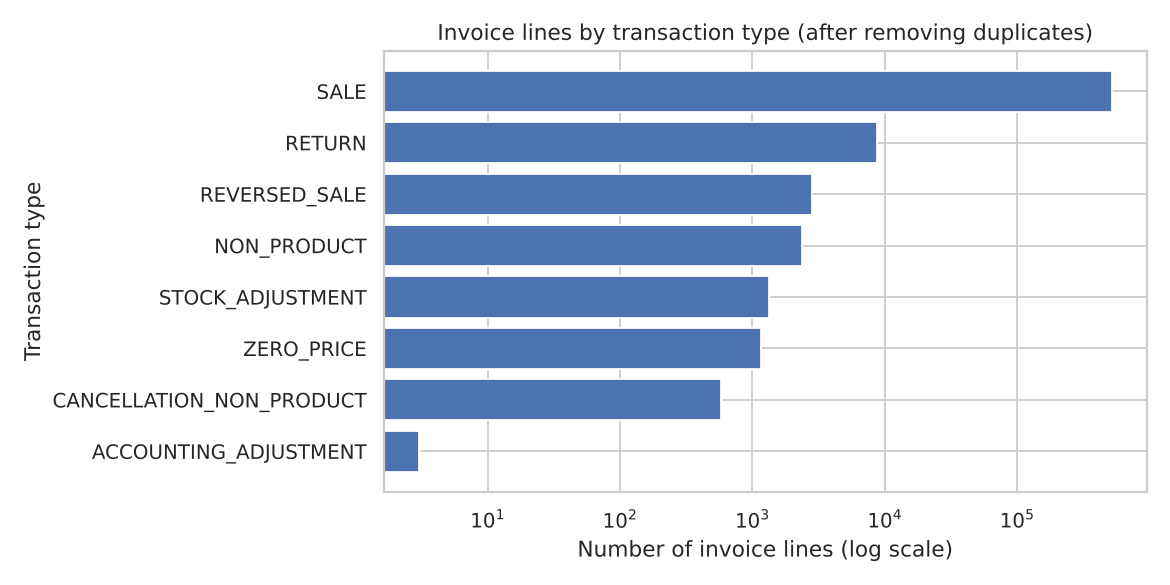

**Business interpretation:** 96.8% of lines are genuine product sales. Returns, reversed orders, postage/fees and adjustments are kept out of demand so they do not distort forecasts.

### Daily sales

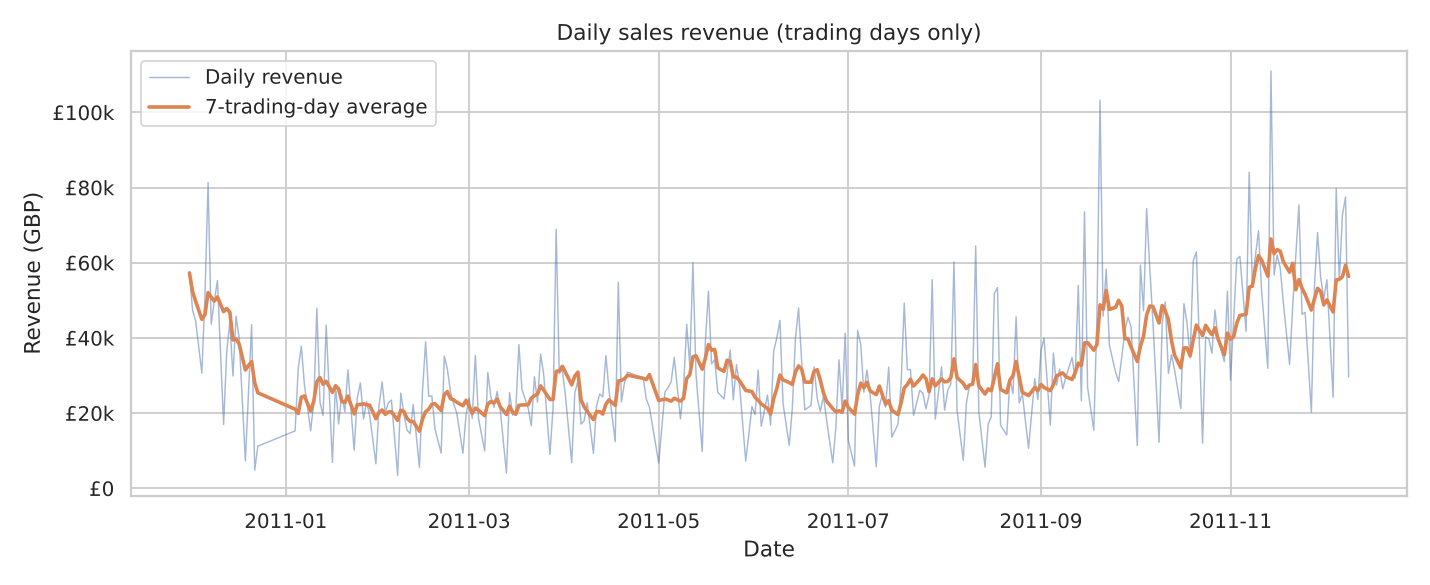

**Business interpretation:** Revenue is noisy day to day (busiest day 14 Nov 2011: £111k; daily std = £17k). Average revenue per trading day is highest in December 2011 (£56k), 2.6x the lowest month (February 2011).

### Weekly sales

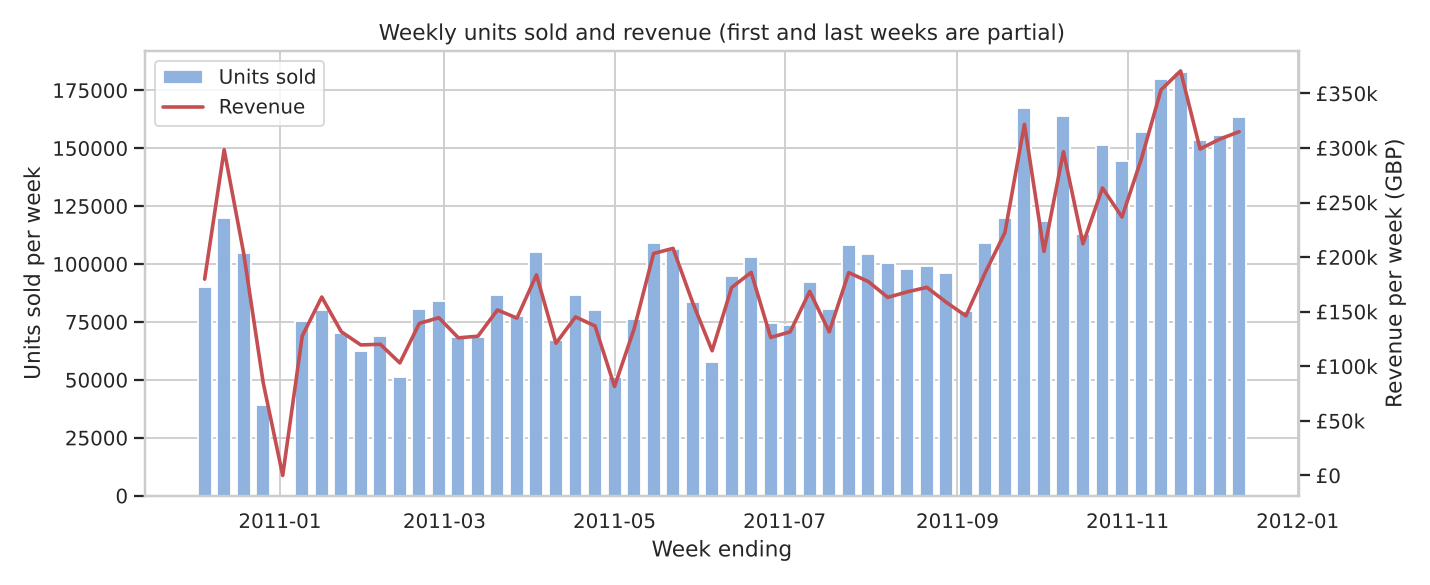

**Business interpretation:** Units and revenue move together. Full weeks range from £82k to £371k revenue, so weekly planning must allow for a large swing. 1 week(s) had no trading at all (holiday closure).

### Monthly revenue

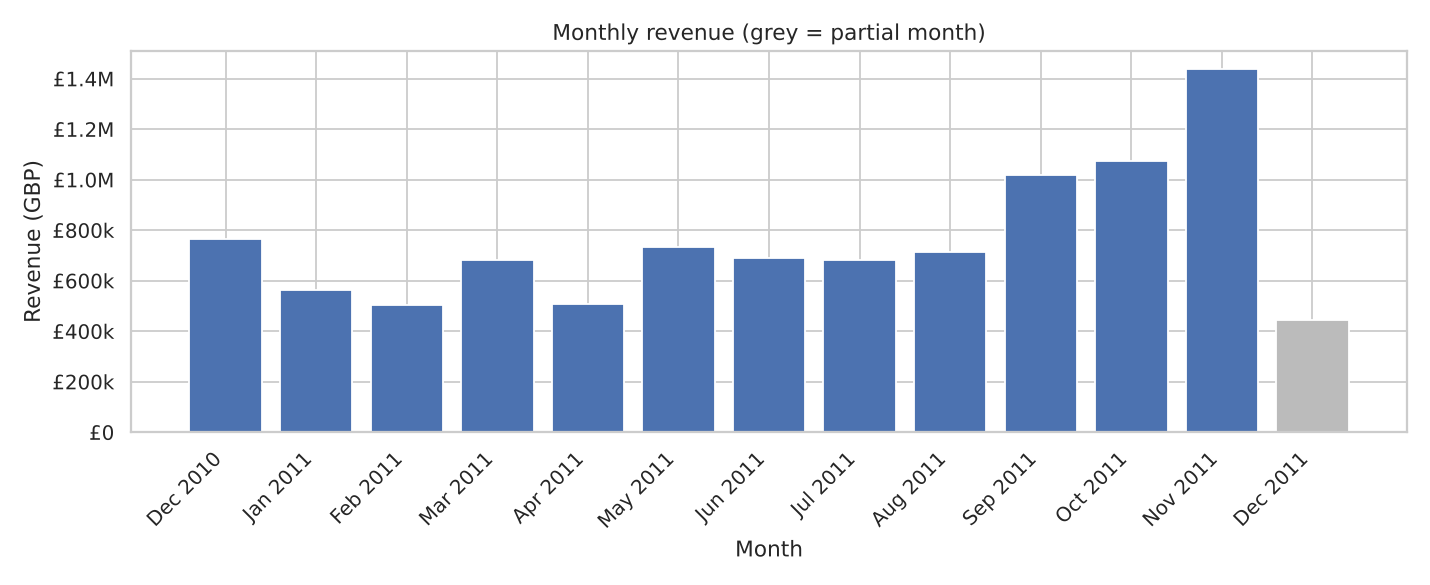

**Business interpretation:** Best full month: November 2011 (£1.4M); weakest: February 2011 (£505k). With only ~one year of data this is a single seasonal cycle, so it is described as an observed peak in this period, not a proven yearly pattern.

### Top 10 products by units sold

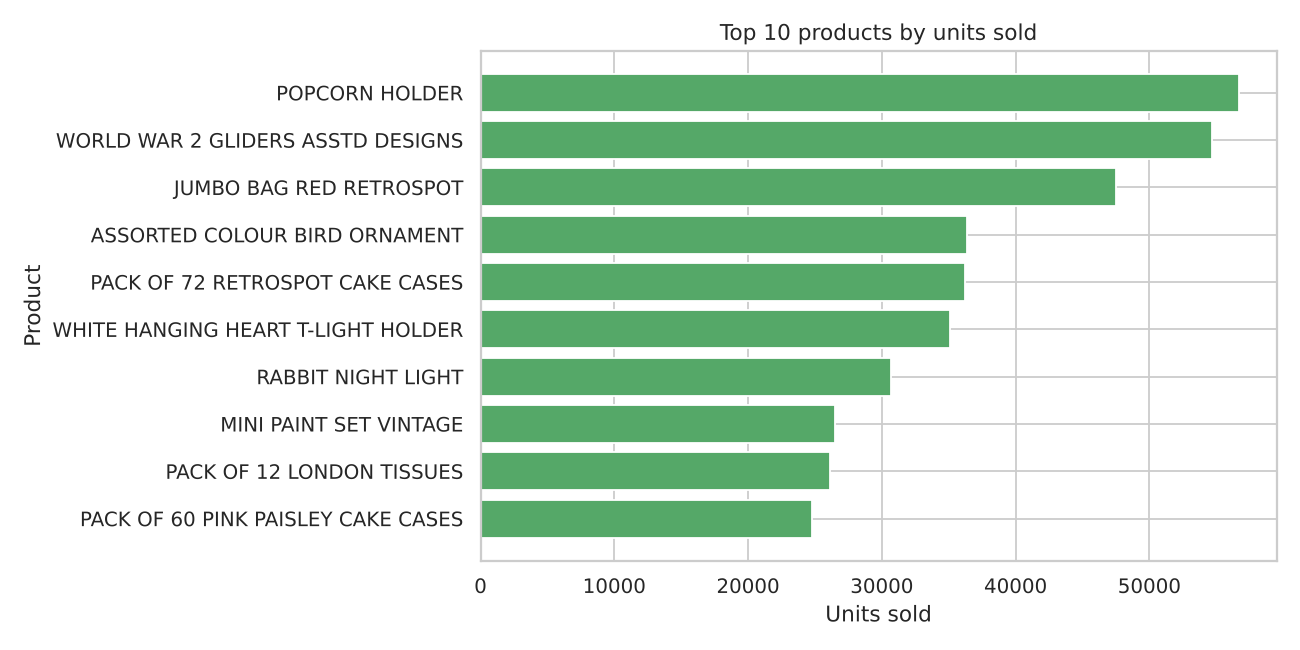

**Business interpretation:** 'POPCORN HOLDER' leads with 56,676 units. These 10 products account for 7.0% of all units; their average selling price is £1.17 per unit.

### Top 10 products by revenue

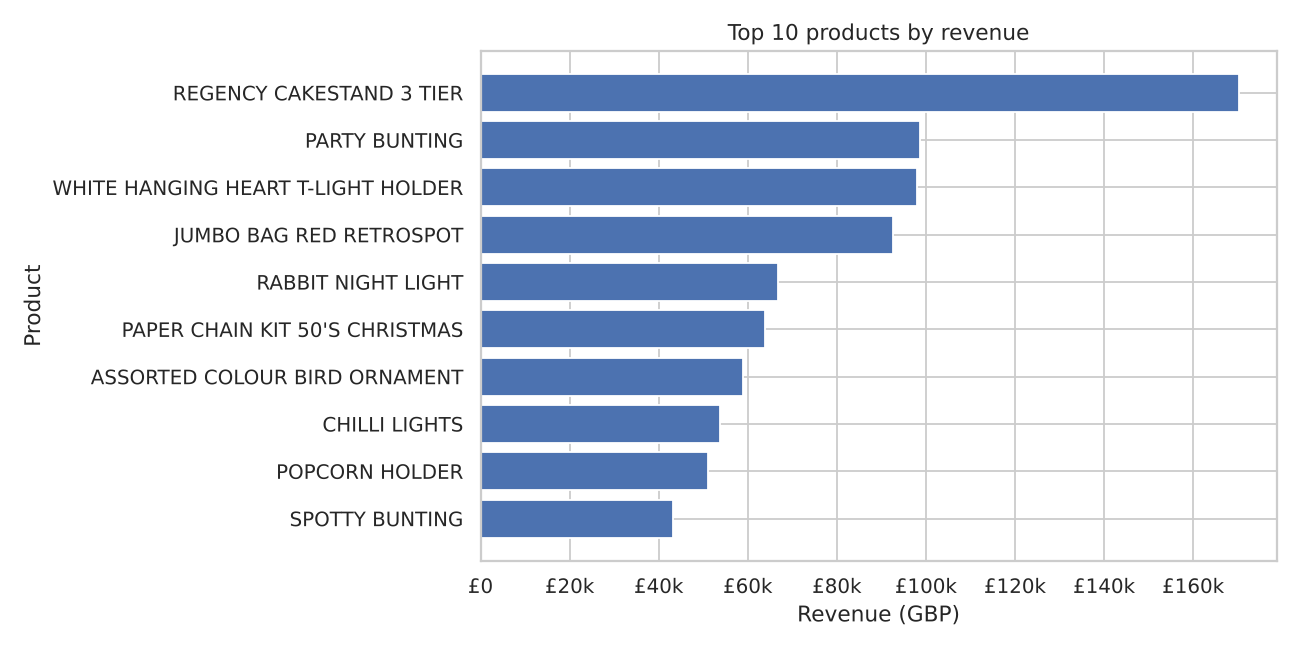

**Business interpretation:** 'REGENCY CAKESTAND 3 TIER' leads with 170,229 GBP. These 10 products account for 8.1% of all revenue; their average selling price is £2.89 per unit.

### Product demand variability

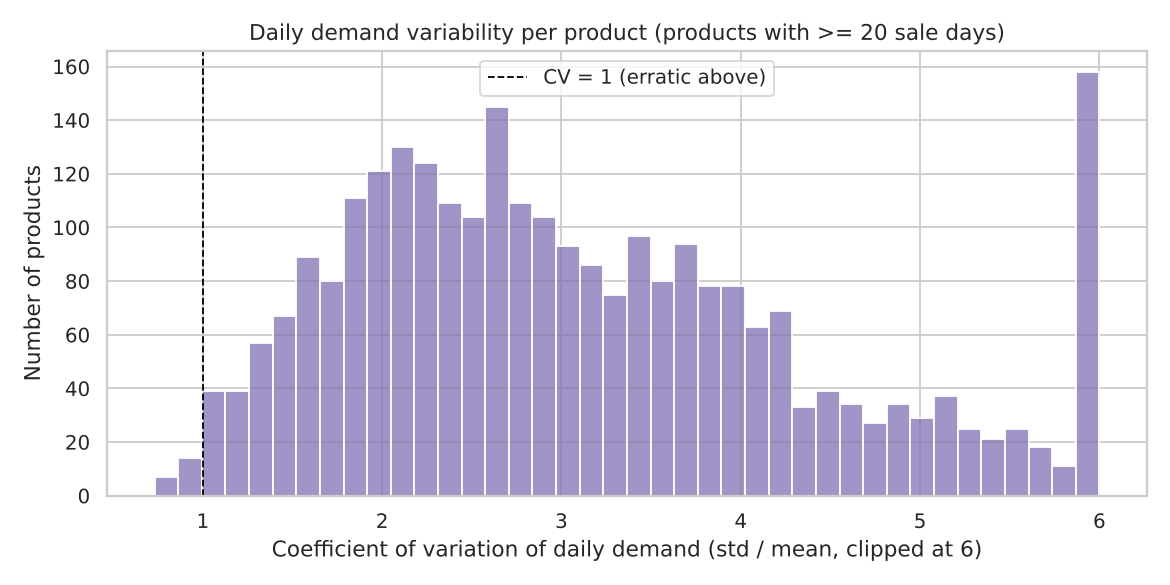

**Business interpretation:** 99% of products with >= 20 sale days have CV > 1 (median CV 2.87; median share of trading days with a sale 34%). Daily product demand is intermittent and bursty, so safety stock matters and day-level forecast errors will be large.

### Country-wise revenue

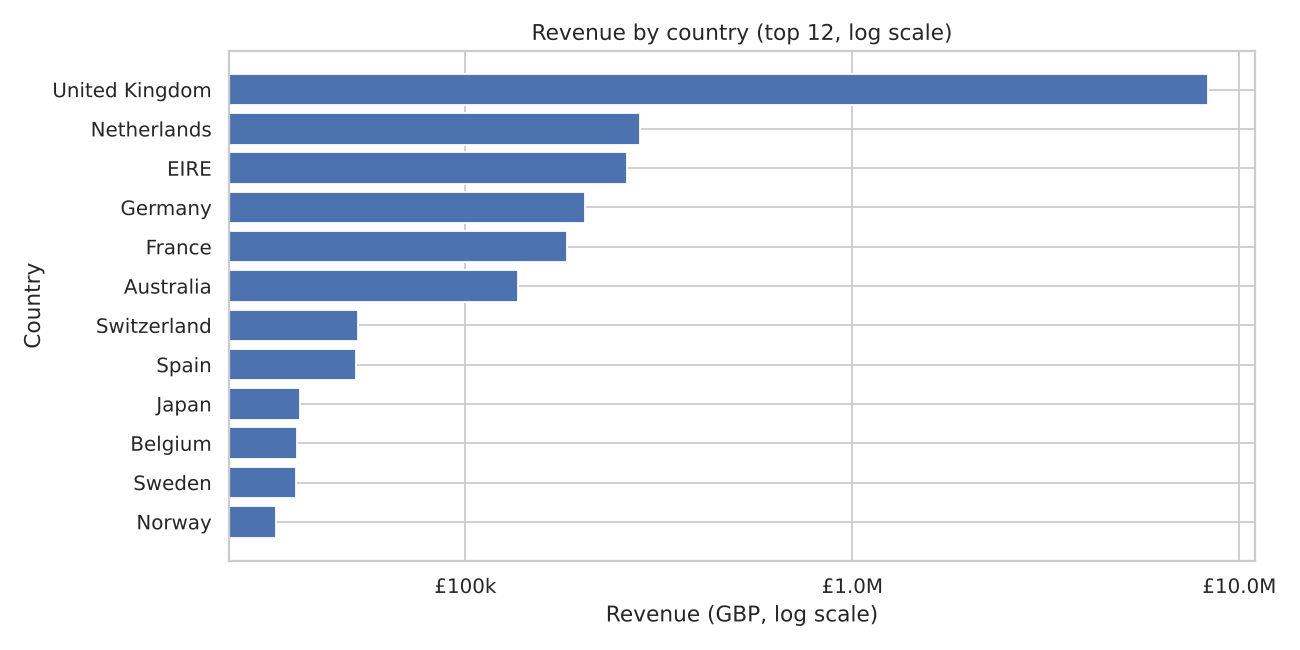

**Business interpretation:** United Kingdom generates 84.7% of revenue; a log scale keeps the next markets (Netherlands, EIRE, Germany, France) visible. Demand is dominated by one market.

### Day-of-week pattern

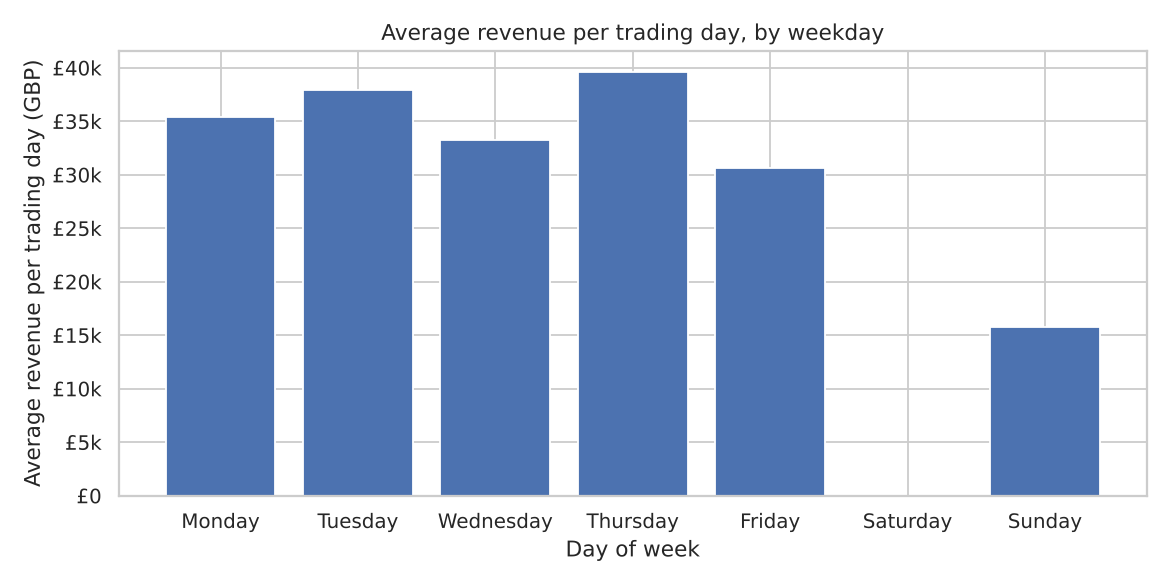

**Business interpretation:** Busiest weekday: Thursday; quietest: Sunday. No trading on: Saturday — the forecast treats these as closed days.

### Hourly pattern

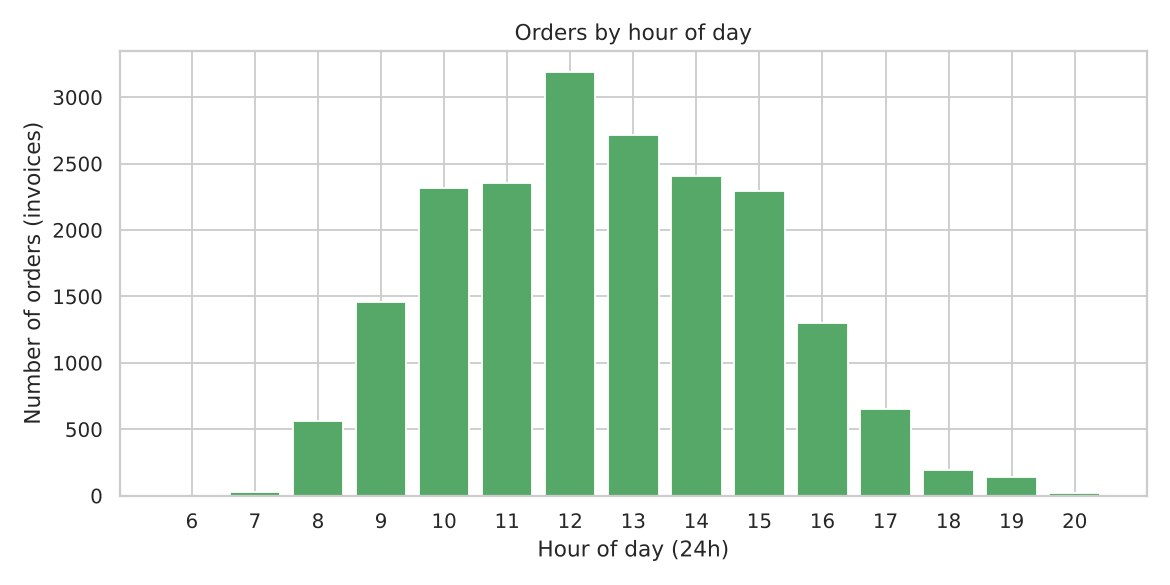

**Business interpretation:** Orders peak around 12:00; 98.1% of orders arrive between 08:00 and 17:59 (first hour with orders: 6:00, last: 20:00).

### Customer purchase frequency

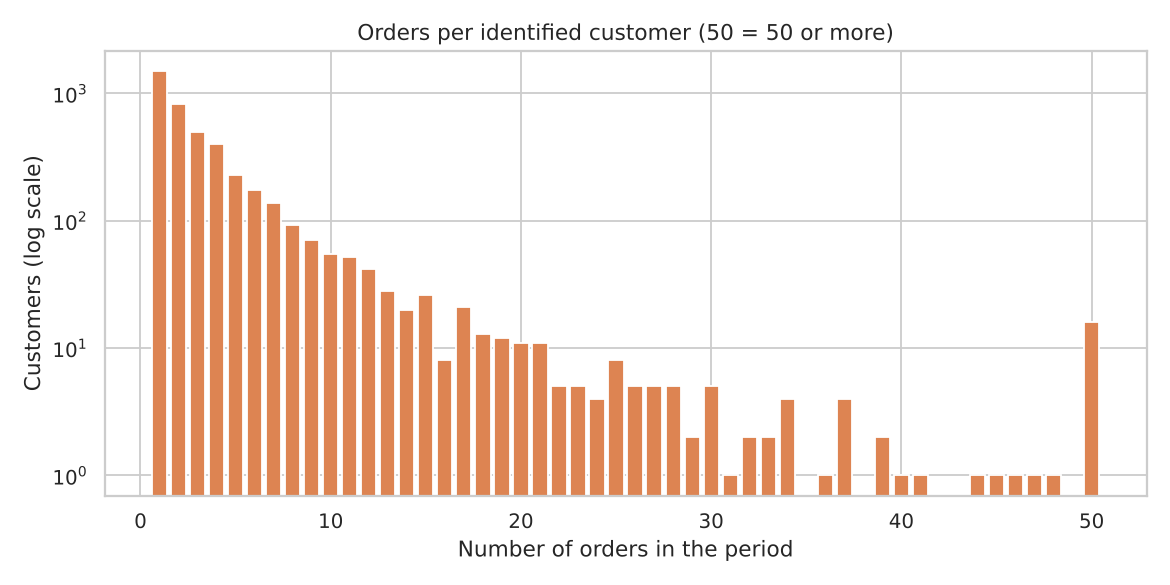

**Business interpretation:** 65% of identified customers ordered more than once (median 2 orders, maximum 203). Identified customers generate 84.6% of revenue.

In [6]:
report = eda.generate_eda(sales, classified)
for c in report["charts"]:
    display(Markdown(f"### {c['title']}"))
    display(Image(filename=str(config.REPORTS_DIR / c["file"]), width=900))
    display(Markdown(f"**Business interpretation:** {c['interpretation']}"))

## 4. Product analysis
Top 10 by units and revenue, least-selling products, and product-wise revenue/demand.

In [7]:
display(eda.top_products(sales, "quantity", 10)[["StockCode", "Description", "quantity", "revenue", "sale_days"]])
display(eda.top_products(sales, "revenue", 10)[["StockCode", "Description", "quantity", "revenue", "revenue_share_pct"]])
display(eda.slow_moving_products(sales, 10)[["StockCode", "Description", "quantity", "sale_days", "last_sale"]])

,StockCode,Description,quantity,revenue,sale_days
0,22197,POPCORN HOLDER,56676,51171.77,294
1,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54711,13744.41,235
2,85099B,JUMBO BAG RED RETROSPOT,47490,92601.23,300
3,84879,ASSORTED COLOUR BIRD ORNAMENT,36333,58878.61,300
4,21212,PACK OF 72 RETROSPOT CAKE CASES,36228,21154.05,298
5,85123A,WHITE HANGING HEART T-LIGHT HOLDER,35117,97988.95,305
6,23084,RABBIT NIGHT LIGHT,30709,66807.63,136
7,22492,MINI PAINT SET VINTAGE,26489,16844.22,208
8,22616,PACK OF 12 LONDON TISSUES,26107,7971.30,239
9,21977,PACK OF 60 PINK PAISLEY CAKE CASES,24748,12186.72,277


,StockCode,Description,quantity,revenue,revenue_share_pct
0,22423,REGENCY CAKESTAND 3 TIER,13506,170229.39,1.7329
1,47566,PARTY BUNTING,18091,98614.83,1.0039
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,35117,97988.95,0.9975
3,85099B,JUMBO BAG RED RETROSPOT,47490,92601.23,0.9427
4,23084,RABBIT NIGHT LIGHT,30709,66807.63,0.6801
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,18962,63936.94,0.6509
6,84879,ASSORTED COLOUR BIRD ORNAMENT,36333,58878.61,0.5994
7,79321,CHILLI LIGHTS,10225,53761.61,0.5473
8,22197,POPCORN HOLDER,56676,51171.77,0.5209
9,23298,SPOTTY BUNTING,8462,43128.38,0.4390


,StockCode,Description,quantity,sale_days,last_sale
0,84227,HEN HOUSE W CHICK IN NEST,1,1,2011-03-14
1,51014c,"FEATHER PEN,COAL BLACK",1,1,2011-10-31
2,90084,PINK CRYSTAL GUITAR PHONE CHARM,1,1,2011-03-06
3,84743C,ORANGE FELT VASE + FLOWERS,1,1,2011-03-31
4,37461,FUNKY MONKEY MUG,1,1,2010-12-05
5,84569C,PACK 4 FLOWER/BUTTERFLY PATCHES,1,1,2011-03-25
6,84977,WIRE FLOWER T-LIGHT HOLDER,1,1,2011-03-18
7,35597A,DUSTY PINK CHRISTMAS TREE 30CM,1,1,2010-12-06
8,21009,ETCHED GLASS STAR TREE DECORATION,1,1,2010-12-17
9,35597B,BLACKCHRISTMAS TREE 30CM,1,1,2010-12-06


### Product demand variability
Coefficient of variation (CV = std / mean of daily demand) per product over its observation window.

In [8]:
var = eda.demand_variability(sales, min_sale_days=20)
display(var["variability_class"].value_counts())
display(var[["StockCode", "Description", "mean_daily_demand", "std_daily_demand", "cv", "sale_day_ratio"]].head(10))

variability_class
Erratic     2731
Moderate      22
Name: count, dtype: int64[pyarrow]

,StockCode,Description,mean_daily_demand,std_daily_demand,cv,sale_day_ratio
0,22688,DOORMAT PEACE ON EARTH BLUE,2.3191,36.3785,15.6865,0.0855
1,22053,EMPIRE DESIGN ROSETTE,15.7185,237.7582,15.1260,0.0963
2,22102,MIRROR MOSAIC T-LIGHT HOLDER,3.1429,45.9855,14.6316,0.0976
3,72803A,ROSE SCENT CANDLE JEWELLED DRAWER,1.9167,24.5824,12.8254,0.1413
4,22105,MIRROR MOSAIC GOBLET CANDLE HOLDER,1.1060,13.8553,12.5274,0.0993
5,22687,DOORMAT CHRISTMAS VILLAGE,2.6577,31.9682,12.0285,0.1441
6,22476,EMPIRE UNION JACK TV DINNER TRAY,2.8590,34.3803,12.0253,0.3049
7,22702,BLACK AND WHITE CAT BOWL,4.5892,52.1246,11.3581,0.1549
8,22350,ILLUSTRATED CAT BOWL,4.6349,51.7118,11.1570,0.3125
9,47481,50CM METAL STRING WITH 7 CLIPS,0.7705,8.5405,11.0844,0.0788


## 5. Customers and countries

In [9]:
cust = eda.customer_summary(sales)
display(pd.Series({k: v for k, v in cust.items() if not isinstance(v, (list, dict))}, name="value").to_frame())
display(pd.DataFrame(cust["top_customers"]))
display(eda.country_summary(sales).head(10))

,value
identified_customers,4324.00
revenue_share_identified_pct,84.63
one_time_customers_pct,34.74
repeat_customers_pct,65.26


,CustomerID,revenue,orders,country
0,14646,278742.02,72,Netherlands
1,18102,259657.30,60,United Kingdom
2,17450,189607.53,45,United Kingdom
3,14911,129667.33,195,EIRE
4,12415,123806.88,19,Australia
5,14156,113866.28,54,EIRE
6,17511,88556.38,30,United Kingdom
7,16684,65920.12,28,United Kingdom
8,13694,63555.30,50,United Kingdom
9,16029,62205.93,59,United Kingdom


,Country,revenue,quantity,transactions,customers,revenue_share_pct,average_order_value
0,United Kingdom,8321965.96,4425770,17792,3909,84.715,467.74
1,Netherlands,283443.54,199934,93,9,2.885,3047.78
2,EIRE,261662.56,143112,279,3,2.664,937.86
3,Germany,203849.48,117227,443,94,2.075,460.16
4,France,182834.59,109884,380,87,1.861,481.14
5,Australia,137124.05,83464,53,9,1.396,2587.25
6,Switzerland,52712.50,30281,48,21,0.537,1098.18
7,Spain,52029.97,26655,87,29,0.530,598.05
8,Japan,37314.37,25976,19,8,0.380,1963.91
9,Belgium,36813.69,22927,98,25,0.375,375.65


## 6. Time patterns

In [10]:
display(eda.day_of_week_pattern(sales))
display(eda.hourly_pattern(sales))

,day_of_week,revenue,quantity,transactions,trading_days,avg_revenue_per_trading_day
0,Monday,1663783.29,858368,3051.0,47,35399.64
1,Tuesday,1970337.28,1020548,3485.0,52,37891.10
2,Wednesday,1764575.33,1015308,3646.0,53,33293.87
3,Thursday,2100009.31,1188924,4185.0,53,39622.82
4,Friday,1533946.95,796460,3086.0,50,30678.94
5,Saturday,0.00,0,0.0,0,0.00
6,Sunday,790807.21,458490,2195.0,50,15816.14


,hour,transactions,revenue,quantity
0,6,1,4.25,1
1,7,29,30469.21,15360
2,8,563,277503.21,157500
3,9,1461,777968.79,432048
4,10,2317,1303225.62,723904
5,11,2358,1181001.60,663249
6,12,3191,1372434.25,817729
7,13,2718,1209140.45,694267
8,14,2409,1106403.66,589646
9,15,2295,1225868.52,620138


In [11]:
from ml.utils import atomic_write_json, atomic_write_text
atomic_write_json(config.REPORTS_DIR / "02_eda_report.json", report)
atomic_write_text(config.REPORTS_DIR / "02_eda_report.md", eda.render_markdown(report))
print("Saved data/reports/02_eda_report.{json,md}")
print(report["seasonality_note"])

Saved data/reports/02_eda_report.{json,md}
The data covers ~12 months (Dec 2010 - Dec 2011): one seasonal cycle. Annual seasonality cannot be statistically confirmed.
